<a href="https://colab.research.google.com/github/ashah778/Data-201-Assignments/blob/main/Arnav%20Shah%20-%20Week%209%20HW%20Decision%20Tree%20Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Installing the ISLP
%pip -q install ISLP


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Importing he libraries needed to load the dataset to organize the data,
# and create graphs.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# importing the tools needed to split the data,
# perform cross validation and build decision trees
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

Part 1: Build a Classification Tree

1. Load the Carseats dataset and create the binary target HighSales. (copy the code from
the lab)


In [3]:
# Source: Week 9 Lab

from ISLP import load_data

# Loading the Carseats Dataset
carseats = load_data('Carseats')
carseats.head()




,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
# Creating a binary target where Sales above 8 is High Sales
# Removing the original Sales column
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Printing and checking the number of stores that are in each category

print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


2. Encode Categorical Predictors

In [5]:
# Source: Week 9 Lab

# Seperating the predictors from the target variable
# Setting HighSales as my target variable

X = pd.get_dummies(carseats.drop(columns='HighSales'),columns=['ShelveLoc', 'Urban', 'US']).astype(int)

y = carseats['HighSales']


3. Split the data into 70% training and 30% test sets

In [40]:
# Source: Week 9 Lab

# Splitting the data into 70% training and 30% testing
# Stratify secured the proportion for High and Low Sales in both of the sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# Printing the training and testing data to check the size for my training and testing sets

print('Training data:', X_train.shape)
print('Test data:', X_test.shape)

X_train.head()

Training data: (280, 14)
Test data: (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
69,127,59,0,339,99,65,12,0,0,1,0,1,1,0
273,116,106,8,244,86,58,12,0,0,1,0,1,0,1
226,119,33,0,245,122,56,14,0,1,0,0,1,1,0
305,115,29,26,394,132,33,13,0,0,1,0,1,0,1
92,114,113,0,97,125,29,12,0,0,1,0,1,1,0


4. Train a DecisionTreeClassifier with max_depth = 3.


In [56]:
# Source: Week 9 Lab

# Creating a decision tree with a maximum depth of 3
# Training the decision tree using my training data

tree2 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree2.fit(X_train,y_train)




DecisionTreeClassifier(max_depth=3, random_state=42)

5. Plot the tree and report training and test accuracy.


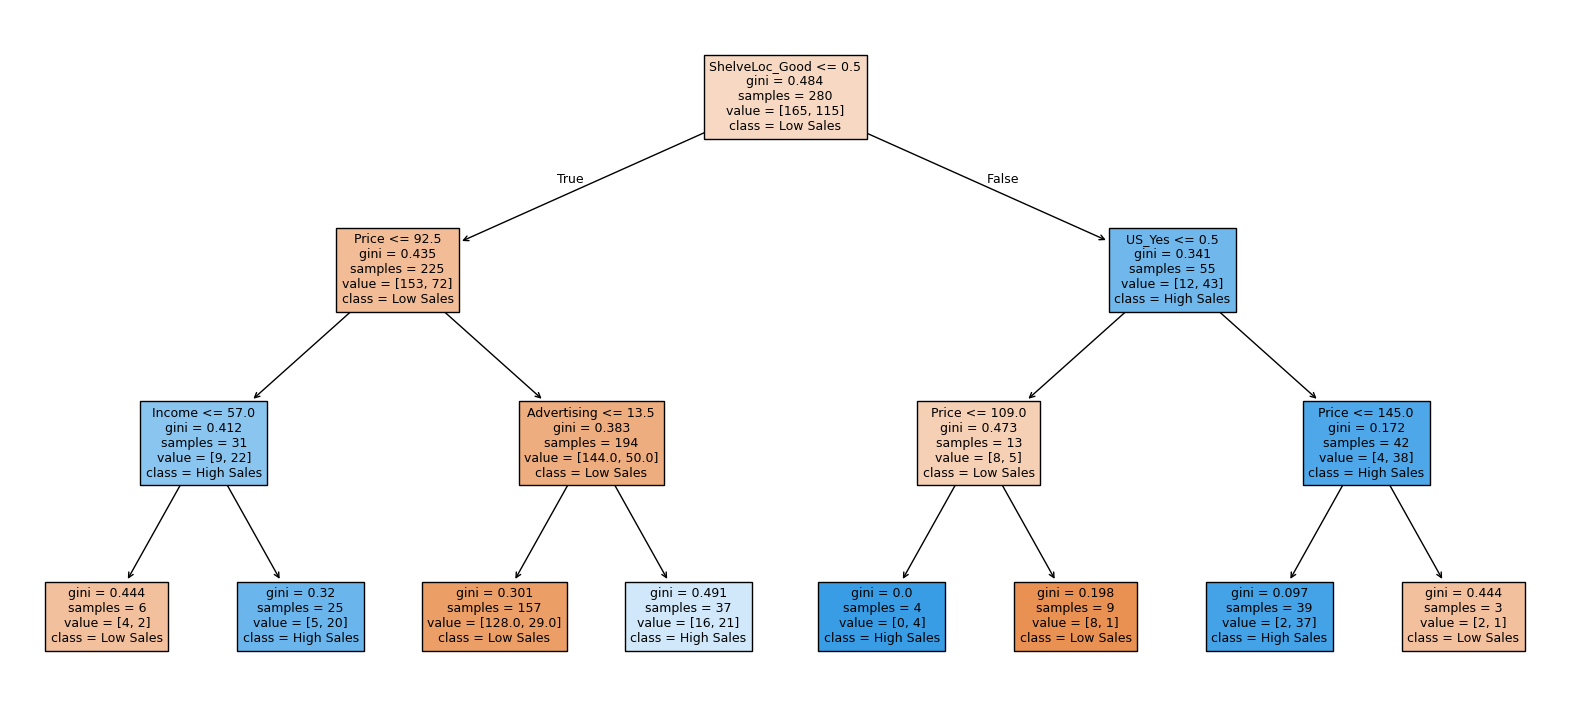

Train accuracy: 0.8
Test accuracy: 0.8


In [58]:
# Source: Week 9 Lab

# Plotting my decision tree to view the way it creates predictons

plt.figure(figsize=(20,9))

plot_tree(tree2,
          feature_names=list(X.columns),
          class_names=['Low Sales','High Sales'],
          filled=True,
          fontsize=9
)
plt.show()


# Printing the training and testing accuracy to see what it is for training and testing data

print('Train accuracy:', round(tree2.score(X_train,y_train),3))
print('Test accuracy:', round(tree2.score(X_test,y_test),3))

Part 2: Investigate Overfitting

1. Test different tree depths

2. Calculate 5-fold cross-validation accuracy

In [59]:
# Source: Week 9 Lab

# Setting the tree depths from 1 to 10
depths = range(1, 11)

# Initializing an empty list for the cross-validation accuracies
cv_acc = []

# Testing the tree depth by implementing 5-fold cross-validation
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    scores = cross_val_score(m, X_train, y_train, cv=5)
    cv_acc.append(scores.mean())


3. Create a graph showing tree depth versus cross-validation accuracy.

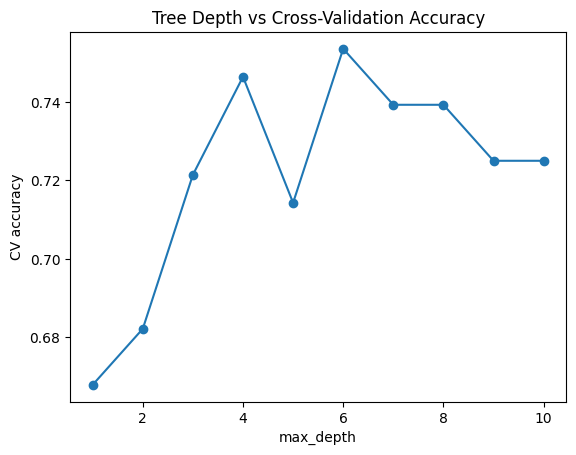

In [60]:
# Source: Week 9 Lab


# Plotting cross-validation accuracy that occurs for each tree depth
plt.plot(depths, cv_acc, marker='o')
plt.xlabel('max_depth')
plt.ylabel('CV accuracy')
plt.title('Tree Depth vs Cross-Validation Accuracy')
plt.show()



4. Identify the best depth based on cross-validation.

In [61]:

# Source: Week 9 Lab

# Finding the depth which has the highest accuracy for cross-validation

best_d = list(depths)[int(np.argmax(cv_acc))]

# Printing the best max depth as well as best cross validation accuracy

print('Best max_depth:', best_d)

print('Best CV accuracy:', round(cv_acc[int(np.argmax(cv_acc))], 3))

Best max_depth: 6
Best CV accuracy: 0.754


5. Train a final tree using that depth and evaluate it on the test set.

In [62]:
# Source: Week 9 Lab


# Training the final decision tree by impplementing the best depth

best_tree = DecisionTreeClassifier(max_depth=best_d, random_state=0).fit(X_train, y_train)

# Checking test accuracy for the final tree in the test data

print('Test accuracy:', round(best_tree.score(X_test, y_test), 3))

Test accuracy: 0.725


Part 3: Answer the Following Questions

1. Which predictor was selected for the first split (root)? What does
this split tell us about sales?

The root predictor is ShelveLoc_Good. It is the first variable which is selected by the decision tree to separate stores into groups.

It implements the predictor by assisting in distinguishing between stores with high sales and stores with low sales. The first split displays how the shelf location is useful for predicting whether a store has high or low sales.


2. According to your cross-validation graph, which depth performed
best? Why should we use cross-validation rather than test accuracy to choose the depth?

A tree depth of 6 performed the best with an accuracy at about 75.5%. After that accuracy decreased to about 73.8% at depths 7 and 8 then eventually dropped to around 72.5% at depths 9 and 10.

We can use cross-validation the reason is because it tests the model across the five different training/validation splits. As a result it helps us make a decision regarding what the best depth is without involving the data that uses testing.

3.  Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph.

No I think increasing tree depth does not always improve the cross-validation accuracy. According to my graph the accuracy increased until a depth of 6 which reached at about 75.5%.

Afterwards it decreased to about 73.8% for depths 7 and 8 then it dropped to about 72.5% at depths 9 and 10. Therefore this explains why deeper trees do not always have a better performance overall.

Wrap-Up Questions (From the Week 9 Lab):


1. What does a leaf predict in a classification tree? In a regression tree?

A leaf is the final point of a tree where a prediction is made. A classification tree predicts the most common class. For example in Section 2 the Heart tree predicts Yes or No for AHD.

A regression tree predicts the average value. For example in Section 7 the Hitters tree predicts the average log salary for players in that leaf.

2. Why did the full tree reach 100% training accuracy but do worse on the test set?

The full tree reached a 100% training accuracy because it memorized all the patients in the training set. This is called overfitting which happens when the model learns the training data too closely.

In Section 4 from a max_depth of 8 to 15, the training accuracy stayed flat at 1.00 meanwhile the test accuracy was way lower at its peak of 0.80 at a depth of about 5.

It did really well on the data that it was trained on but it did not do as well with new patients in the test set. This shows that the tree did not perform as well on new data.


3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?

I think two ways to limit tree complexity are max_depth and min_samples_leaf. I learned that max_depth sets the maximum number of levels in a tree.

Also I learned that min_samples_leaf sets the minimum number of observations that must be in each leaf. In Section 5, I learned that GridSearchCV uses 5-fold cross-validation which means it divides the training data into five parts.

It essentially trains on four parts and tests on the remaining thing and repeats this process five times. In Section 5, cross-validation helped me tune both max_depth and min_samples_leaf to help it perform better to find the best tree complexity.

4. Why do we not need to scale features before fitting a tree?

We do not need to scale features since scaling means to change the range of feature values to make them on a similar scale.

The goal of Decision Trees is to basically to compare values at certain cutoffs. Scaling does not change the order of the values which is why it does not affect the way the trees split.

5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

I don't think this is correct because an importance of 0 only means that Age did not reduce impurity in the tree's splits. In Section 6, the lab showed that the tree used the predictors such as ChestPain_asymptomatic and Ca to make the splits.

Age might not have been necessary or needed since the other predictors assisted in separate patients with as well as without heart disease. However, this does not mean that Age does not have value or does not have relevance.


6. Name one strength and one weakness of a single decision tree that you saw in this lab.

One strength is that decision trees in this lab are easy to understand since I am able to see and follow each split to visualize. I am also able to see and analyze how a prediction is made. For example, in Section 6 the export_text function showed the tree's rules in an if/else format.

One weakness is that trees in this lab can be unstable which means that small changes happen in the training data which end up creating a different tree.

In Part 6 at the end of the lab there is also an implementation of five different random train/test splits. The first feature can change from a different training data. This shows that trees can be unstable.